In [1]:
import pandas as pd
import logging
import matplotlib.pyplot as plt

# create an instance of the logger
logger = logging.getLogger()


# # Change current directory to parent directory
import os
os.chdir("..")

# Load the File


## Getting the SCADA DATA WITH FEATURES

In [2]:
# Define global variables
RAW_PATH_SCADA_FEATURES = "data/processed/scada_with_features.csv"


# Attempt to load the file with a try-except block
try:
    # Check if the file exists
    if os.path.exists(RAW_PATH_SCADA_FEATURES):
        # Load the CSV file
        scada_features_data = pd.read_csv(RAW_PATH_SCADA_FEATURES)
        print("File loaded successfully.")
    else:
        raise FileNotFoundError(f"File not found: {RAW_PATH_SCADA_FEATURES}")
except FileNotFoundError as fnf_error:
    print(fnf_error)
except Exception as e:
    print(f"An error occurred while reading the file: {e}")

File loaded successfully.


## Weekly Production Rates

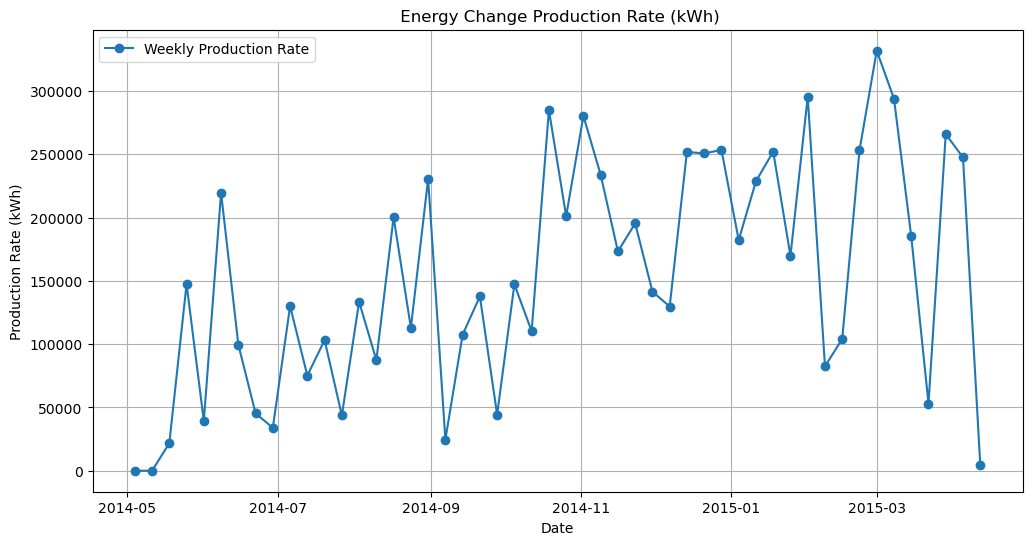

In [3]:
# Ensure the 'DateTime' column is set as the index
scada_features_data.set_index('DateTime', inplace=True)

# Ensure the index is in datetime format
scada_features_data.index = pd.to_datetime(scada_features_data.index, errors='coerce')


# Recalculate weekly and monthly production rates using the corrected production rate column
weekly_production_corrected = scada_features_data['Energy Change'].resample('W').sum()


# Plot corrected weekly production rates
plt.figure(figsize=(12, 6))
plt.plot(weekly_production_corrected.index, weekly_production_corrected.values, label='Weekly Production Rate', marker='o')
plt.title(' Energy Change Production Rate (kWh)')
plt.xlabel('Date')
plt.ylabel('Production Rate (kWh)')
plt.grid(True)
plt.legend()
plt.show()

## Monthly Production Rates


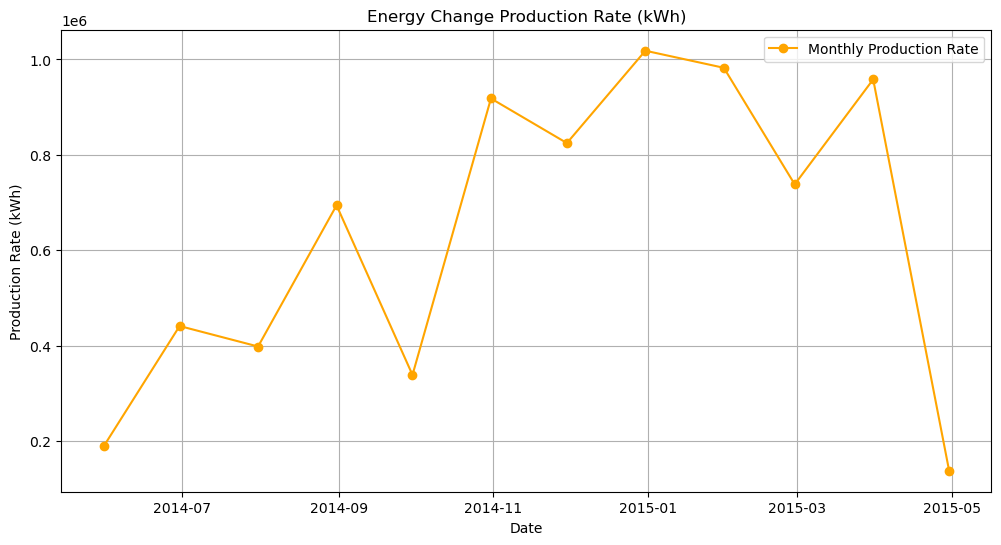

In [4]:
# Recalculate weekly and monthly production rates using the corrected production rate column
monthly_production_corrected = scada_features_data['Energy Change'].resample('M').sum()


# Plot corrected monthly production rates
plt.figure(figsize=(12, 6))
plt.plot(monthly_production_corrected.index, monthly_production_corrected.values, label='Monthly Production Rate', marker='o', color='orange')
plt.title('Energy Change Production Rate (kWh)')
plt.xlabel('Date')
plt.ylabel('Production Rate (kWh)')
plt.grid(True)
plt.legend()
plt.show()

## High Season vs Normal Season Analysis (Depending on the Settlement Point Price gotten from ECROT Market Data 2014 and 2015)

## Weekly Average Setttlement Point Prices

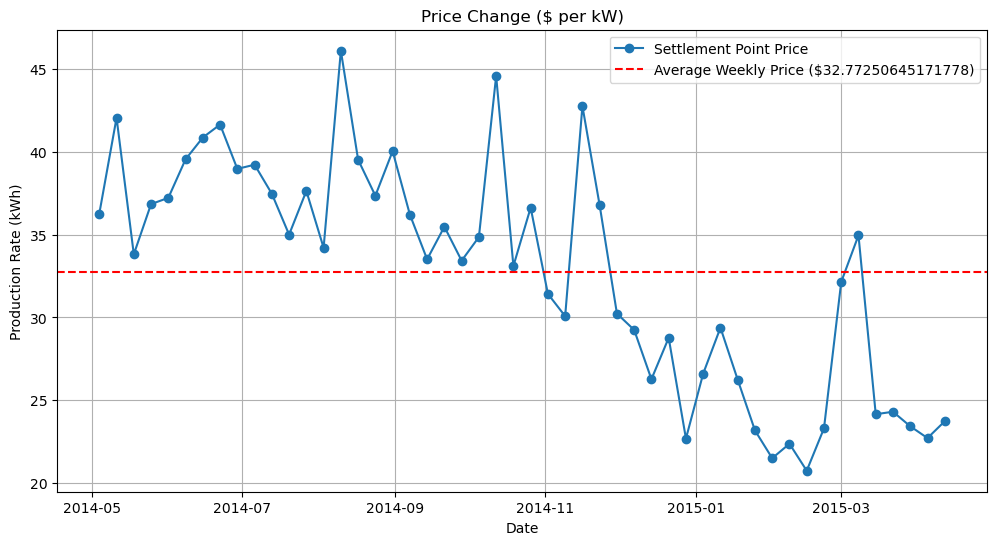

In [5]:
# Recalculate weekly Settlement Point Price
weekly_price_corrected = scada_features_data['Settlement Point Price'].resample('W').mean()

# Define a mean threshold for weekly revenue
mean_price = weekly_price_corrected.values.mean() 


# Plot corrected weekly production rates
plt.figure(figsize=(12, 6))
plt.plot(weekly_price_corrected.index, weekly_price_corrected.values, label='Settlement Point Price', marker='o')
plt.axhline(y=mean_price, color='red', linestyle='--', label=f'Average Weekly Price (${mean_price})')
plt.title('Price Change ($ per kW)')
plt.xlabel('Date')
plt.ylabel('Production Rate (kWh)')
plt.grid(True)
plt.legend()
plt.show()

In [6]:
# Calculate the number of weeks above average price
weeks_above_average = (weekly_price_corrected > mean_price).sum()
total_weeks = len(weekly_price_corrected)
percentage_high_season = (weeks_above_average / total_weeks) * 100

# Print the results
print(f"Number of weeks above average price: {weeks_above_average}")
print(f"Total number of weeks: {total_weeks}")
print(f"Percentage of high season weeks: {percentage_high_season:.2f}%")

Number of weeks above average price: 29
Total number of weeks: 50
Percentage of high season weeks: 58.00%


Using this classification, the percentage of **High Seasons** throughout the year is:

$$
\text{Percentage of High Seasons} = \frac{29}{50} \approx 58.00\%
$$

This insight highlights that High Season months account for approximately 58% of the year, indicating a significant period of heightened market activity. This information can guide resource allocation, marketing strategies, and operational planning during these critical months. **This will be as varaible called high_seasonality=0.4167 for optimization to decide on Maintenance Strategies for determine external vs internal.**

## Monthly Average Setttlement Point Prices

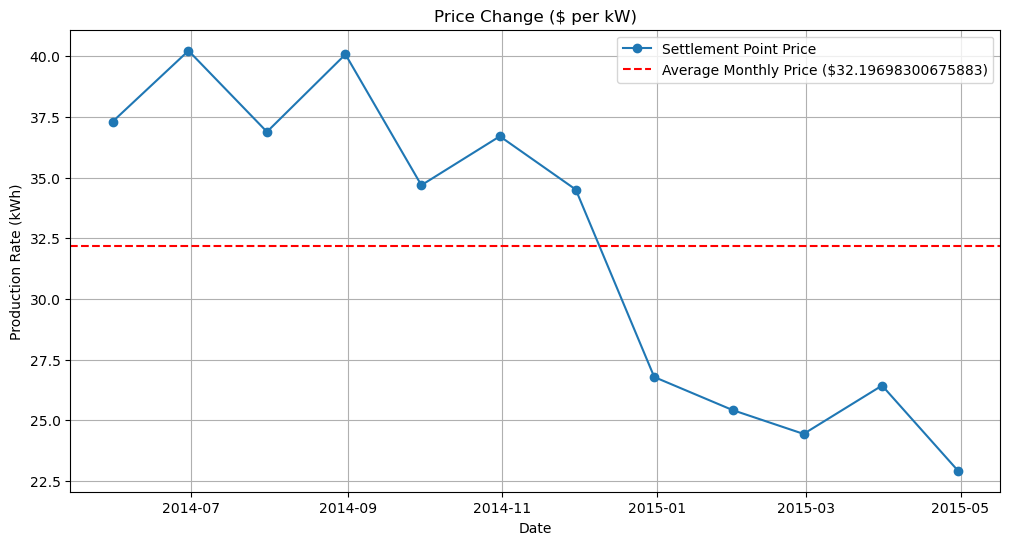

In [7]:
# Recalculate monthly Settlement Point Price
monthly_price_corrected = scada_features_data['Settlement Point Price'].resample('M').mean()

# Define a mean threshold for weekly revenue
mean_price_monthly = monthly_price_corrected.values.mean() 


# Plot corrected weekly production rates
plt.figure(figsize=(12, 6))
plt.plot(monthly_price_corrected.index, monthly_price_corrected.values, label='Settlement Point Price', marker='o')
plt.axhline(y=mean_price_monthly, color='red', linestyle='--', label=f'Average Monthly Price (${mean_price_monthly})')
plt.title('Price Change ($ per kW)')
plt.xlabel('Date')
plt.ylabel('Production Rate (kWh)')
plt.grid(True)
plt.legend()
plt.show()

**The chart depicts the monthly average Settlement Point Price ($/kW) over a specific period (July 2014 to May 2015), with a red horizontal line indicating the overall average price, approximately $32.2 per kW.**

## The plot shows that (according 2014 and 2015):

### The normal season is from December to May
### The high season is from June to November


### Analysis:

Months with Prices Higher than the Average ($32.2/kW):

- **July 2014:** The price is close to $40/kW, significantly higher than the average.
- **August 2014:** Maintains a high value, slightly below July but still above the average.
- **September 2014:** Prices remain above the average.
- **October 2014:** Slightly lower than earlier months but still higher than the average.
- **November 2014:** Prices are marginally above the average.

These months likely reflect a peak season with increased demand or market volatility, driving prices upward.

Months with Prices Lower than the Average ($32.2/kW):

- **December 2014:** Prices fall below the average for the first time, indicating a transition to a lower-demand season.
- **January 2015 to May 2015:** Prices remain consistently below the average, with a noticeable decline over these months. The lowest prices are observed in May 2015.

These months likely correspond to a normal or off-peak season with reduced demand or improved supply conditions, stabilizing or lowering prices.

Key Observations:
- **Peak Period: July to November 2014 sees sustained high prices, suggesting potential seasonal factors (primarily summer high energy demand, because this is in Houston).**
- Off-Peak Period: December 2014 to May 2015 shows a declining trend in prices, possibly reflecting seasonal reductions (less energy demand in Winter month) in energy demand or favorable market conditions.

*This analysis highlights the importance of understanding seasonal evaluating price fluctuations in the energy market.*








## Aggregate revenue on a weekly basis


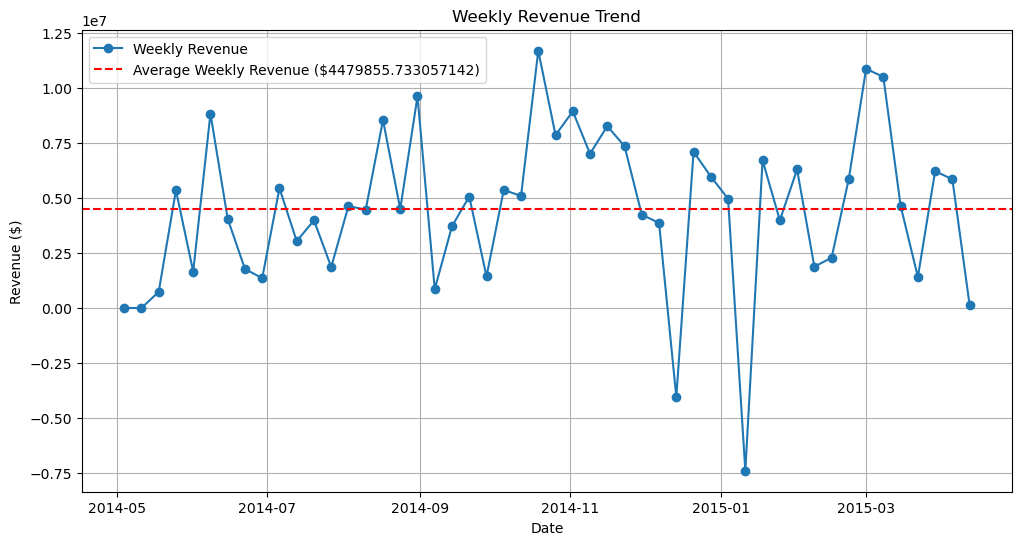

In [8]:
# Aggregate revenue on a weekly basis
weekly_revenue = scada_features_data['Revenue'].resample('W').sum()

# Define a mean threshold for weekly revenue
avg_threshold_w = weekly_revenue.values.mean() 

# Plot weekly revenue
plt.figure(figsize=(12, 6))
plt.plot(weekly_revenue.index, weekly_revenue.values, label='Weekly Revenue', marker='o')
plt.axhline(y=avg_threshold_w, color='red', linestyle='--', label=f'Average Weekly Revenue (${avg_threshold_w})')
plt.title('Weekly Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.grid(True)
plt.legend()
plt.show()

## Aggregate revenue on a monthly basis


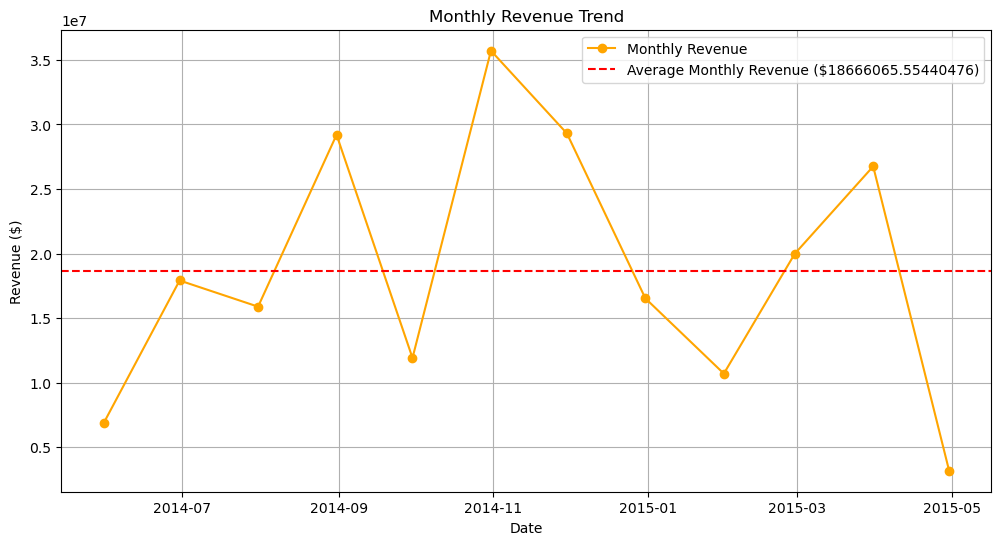

In [9]:
# Aggregate revenue on a monthly basis
monthly_revenue = scada_features_data['Revenue'].resample('M').sum()

# Define a mean threshold for monthly revenue
avg_threshold_m = monthly_revenue.values.mean()

# Plot monthly revenue
plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue.index, monthly_revenue.values, label='Monthly Revenue', marker='o', color='orange')
plt.axhline(y=avg_threshold_m, color='red', linestyle='--', label=f'Average Monthly Revenue (${avg_threshold_m})')
plt.title('Monthly Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.grid(True)
plt.legend()
plt.show()

In [10]:
# Aggregate revenue on a monthly basis
generated_revenue = scada_features_data['Revenue'].sum()

In [14]:
# Print the results
print(f"This the revenue generated from April 2014 to April 2015: ${generated_revenue:.2f}")

This the revenue generated from April 2014 to April 2015: $223992786.65


**Revenue we serve as one of the main optimazation factor which the model will try to maximize to determine an strategy for Maintenance. In our model the $223992786.65 will serve as maxium revenue possible.** 